In [1]:
library(tidyverse)

library(grid)
library(gridExtra)
library(patchwork)

source("../evaluation_utils/plots_eda.R")
source("../evaluation_utils/evaluation_funcs.R")

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors



Attaching package: ‘gridExtra’




The following object is masked from ‘package:dplyr’:

    combine




In [2]:
cbPalette <- c("#CC79A7", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00")

# Load data

In [3]:
data_path <- "../evaluation_data/ovarian_cancer/"

central_uncorrected_path <- paste0(data_path, "before/central_input.tsv")
central_uncorrected_zip_path <- sub("[.]tsv$", ".zip", central_uncorrected_path)
central_uncorrected <- if (file.exists(central_uncorrected_path)) {
    read.csv(central_uncorrected_path, sep = "\t", header = TRUE, row.names = 1, check.names = F)
} else {
    read.delim(unz(central_uncorrected_zip_path, "central_input.tsv"), header = TRUE, row.names = 1, check.names = F)
}
metadata <- read.csv(paste0(data_path, "before/all_metadata.tsv"), sep = "\t", header = TRUE, row.names = 1)

central_corrected <- read.csv(paste0(data_path, "after/label_aware/central_corrected_UNION.tsv"), sep = "\t", header = TRUE, row.names = 1, check.names = F)
fed_corrected <- read.csv(paste0(data_path, "after/label_aware/FedApp_corrected_data.tsv"), sep = "\t", header = TRUE, row.names = 1, check.names = F)

# remove X from row names
rownames(metadata) <- gsub("X", "", rownames(metadata))
metadata$file <- rownames(metadata)
# order the columns in intensity dataframes

central_uncorrected <- central_uncorrected[, rownames(metadata)]

central_corrected <- central_corrected[rownames(central_uncorrected), rownames(metadata)]
fed_corrected <- fed_corrected[rownames(central_uncorrected), rownames(metadata)]

cat("Loaded data")
cat("Central corrected:", nrow(central_corrected), "rows\n")
cat("Central uncorrected:", nrow(central_uncorrected), "rows\n")
cat("Fed corrected:", nrow(fed_corrected), "rows\n")
cat("Sample metadata:", nrow(metadata), "rows\n\n")



Loaded data

Central corrected: 51276 rows


Central uncorrected: 51276 rows


Fed corrected: 51276 rows


Sample metadata: 331 rows



# Checks

## Diagnostic plots

In [4]:
# Same diagnostic panel as the preparation notebook, after central correction.
set.seed(1)  # Same feature subsample on every run.
plot_res <- plots_normtumor(central_corrected[sample(1:nrow(central_corrected), 10000),],
                            metadata %>% mutate(Sample_geo_ID = file), " ", "norm_vs_tumor")
layout <- (plot_res[[1]] + plot_res[[2]]) / (plot_res[[3]])
ggsave(paste0(data_path, "before/plots/norm_vs_tumor_plot_Rcorrected_UNION.png"),
       plot = layout, width = 14, height = 12)

Warning message:
“Removed 1314240 rows containing non-finite outside the scale range
(`stat_density()`).”


Warning message:
“Removed 1314240 rows containing non-finite outside the scale range
(`stat_boxplot()`).”


Warning message:
“Removed 1314240 rows containing non-finite outside the scale range
(`stat_summary()`).”


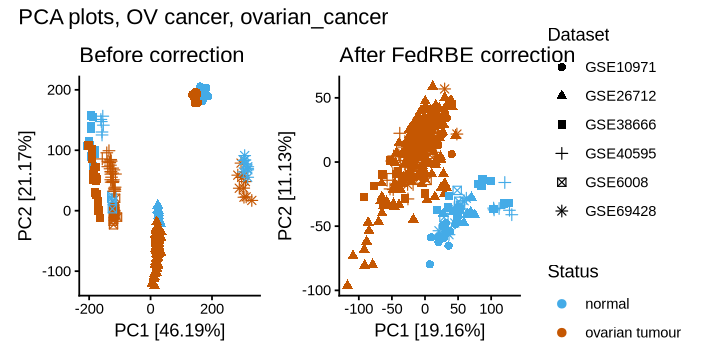

In [5]:
pca_plot_uncorrected <- pca_plot(central_uncorrected, metadata, 
    title = paste("Before correction"),
    quantitative_col_name = "file", col_col= "Status", shape_col ="Dataset", show_legend=F, cbPalette=c("#44abe7", "#c55702"))

# pca_plot_corrected <- pca_plot(central_corrected, metadata, 
#     title = paste("After central correction"),
#     quantitative_col_name = "file", col_col= "Status", shape_col ="Dataset", show_legend=F, cbPalette=c("#44abe7", "#c55702"))
pca_plot_fed <- pca_plot(fed_corrected, metadata, 
    title = paste("After FedRBE correction"),
    quantitative_col_name = "file", col_col= "Status", shape_col ="Dataset", show_legend=T, cbPalette=c("#44abe7", "#c55702"))


layout <- (pca_plot_uncorrected + pca_plot_fed)
# add layout plot title
layout <- layout + plot_annotation("PCA plots, OV cancer, ovarian_cancer")

options(repr.plot.width=6, repr.plot.height=3)
layout

##  Linear model per variable

Following batch effect correction, the percentage of variance explained by the condition should be greater than the batch.

In [6]:
library(variancePartition)

Loading required package: limma



Loading required package: BiocParallel




Attaching package: ‘variancePartition’




The following objects are masked from ‘package:limma’:

    eBayes, topTable




In [7]:
# version of variancePartition package:
packageVersion("variancePartition")

[1] ‘1.40.2’

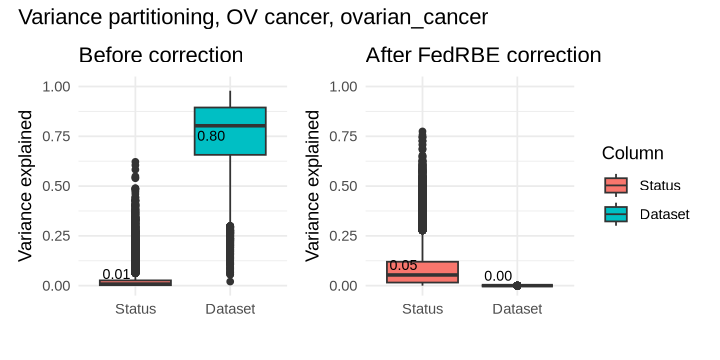

In [8]:
lmpv_plot_uncorrected <- lmpv_plot(central_uncorrected, metadata, 
    title = paste("Before correction"),
    show_legend=F)
# lmpv_plots_corrected <- lmpv_plot(central_corrected, metadata, 
#     title = paste("After central correction"), show_legend=F)
lmpv_plot_fed <- lmpv_plot(fed_corrected, metadata, 
    title = paste("After FedRBE correction"), show_legend=T)


layout <- (lmpv_plot_uncorrected + lmpv_plot_fed)
layout <- layout + plot_annotation("Variance partitioning, OV cancer, ovarian_cancer")
options(repr.plot.width=6, repr.plot.height=3)
layout

# Session info

In [9]:
sessionInfo()

R version 4.5.3 (2026-03-11)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 26.04.1 LTS

Matrix products: default
BLAS/LAPACK: /home/yuliya/repos/cosybio/fedRBE/.pixi/envs/default/lib/libopenblasp-r0.3.34.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Europe/Berlin
tzcode source: system (glibc)

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] variancePartition_1.40.2 BiocParallel_1.44.0      limma_3.66.0            
 [4] viridis_0.6.5            viridisLite_0.4.3        ggsci_5.2.0             
 [7] umap_0.2.10.0            patchwork_1.